In [1]:
# For working with data in table format
import pandas as pd

# For creating graphs and visualisations
import matplotlib.pyplot as plt

# For loading our dataset
from sklearn.datasets import load_breast_cancer

# For splitting data into training and testing sets
from sklearn.model_selection import train_test_split

# For our machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# For evaluating our models
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score
)

In [2]:
# Load the breast cancer dataset
data = load_breast_cancer()
print(data)

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
        1.189e-01],
       [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
        8.902e-02],
       [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
        8.758e-02],
       ...,
       [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
        7.820e-02],
       [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
        1.240e-01],
       [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
        7.039e-02]], shape=(569, 30)), 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0,

In [3]:
# Display feature names
print("Feature Names:")
print(data.feature_names)

# Display target names
print("\nTarget Names:")
print(data.target_names)

# Display dataset shape
print("\nDataset Shape:")
print(data.data.shape)

Feature Names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

Target Names:
['malignant' 'benign']

Dataset Shape:
(569, 30)


In [4]:
# Convert the feature data into pandas DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add the target column to our DataFrame
df["target"] = data.target

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (569, 31)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [7]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


In [8]:
df["target"].value_counts()

,count
target,
1,357
0,212


In [9]:
# Separate the input features
x = df.drop("target", axis=1)

# Separate the target variable
y = df["target"]

In [10]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42, stratify=y)

In [11]:
print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Labels: (455,)
Testing Labels: (114,)


In [47]:
# Create the model
lr_model = LogisticRegression(max_iter=5000)
lr_model.fit(x_train, y_train)

lr_predictions = lr_model.predict(x_test)
print("Predicted Values:")
print(data.target_names[lr_predictions[:10]])

Predicted Values:
['malignant' 'benign' 'malignant' 'benign' 'malignant' 'benign' 'benign'
 'malignant' 'malignant' 'malignant']


In [13]:
print("Actual values:")
print(y_test.values[:10])

print("\nPredicted values:")
print(lr_predictions[:10])

Actual values:
[0 1 0 1 0 1 1 0 0 0]

Predicted values:
[0 1 0 1 0 1 1 0 0 0]


In [28]:
lr_accuracy = accuracy_score(y_test, lr_predictions)
print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.9649122807017544


In [17]:
print("Classification report\n",classification_report(y_test, lr_predictions, target_names= data.target_names, zero_division=0))

Classification report
               precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



[[39  3]
 [ 1 71]]


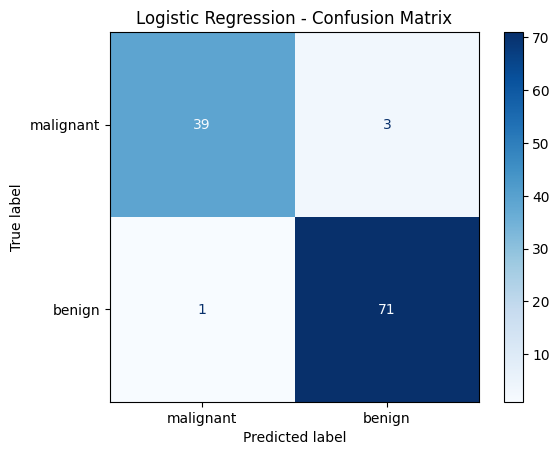

In [19]:
cm = confusion_matrix(y_test, lr_predictions)
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [49]:
# Random forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(x_train, y_train)

rf_predictions = rf_model.predict(x_test)
print(data.target_names[rf_predictions[:10]])

['malignant' 'benign' 'malignant' 'malignant' 'malignant' 'benign'
 'benign' 'malignant' 'malignant' 'malignant']


In [23]:
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.956140350877193


In [25]:
print("Classification Report:\n",classification_report(y_test, rf_predictions, target_names=data.target_names, zero_division=0))

Classification Report:
               precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



[[39  3]
 [ 2 70]]


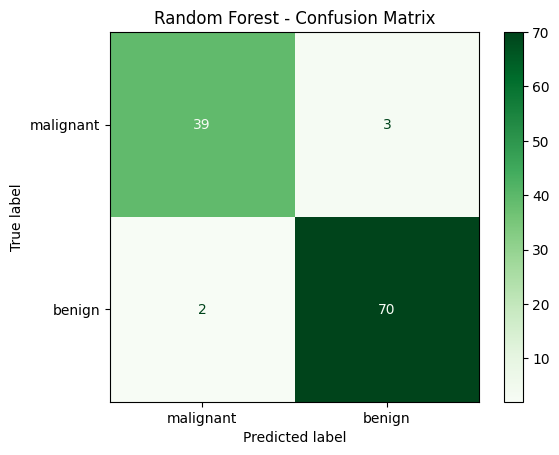

In [26]:
rf_cm = confusion_matrix(y_test, rf_predictions)
print(rf_cm)

ConfusionMatrixDisplay(confusion_matrix=rf_cm, display_labels=data.target_names).plot(cmap="Greens")

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [29]:
print("MODEL COMPARISON")
print("-------------------------")

print("Logistic Regression Accuracy:", lr_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

MODEL COMPARISON
-------------------------
Logistic Regression Accuracy: 0.9649122807017544
Random Forest Accuracy: 0.956140350877193


In [38]:
lr_recall = recall_score(y_test, lr_predictions, pos_label=0)
rf_recall = recall_score(y_test, rf_predictions, pos_label=0)

lr_precision = precision_score(y_test, lr_predictions, pos_label=0)
rf_precision = precision_score(y_test, rf_predictions, pos_label=0)

lr_f1 = f1_score(y_test, lr_predictions, pos_label=0)
rf_f1 = f1_score(y_test, rf_predictions, pos_label=0)

print("Logistic Regression                         Random Forest")
print("Precision:", lr_precision, "                          ", rf_precision)
print("Recall:   ", lr_recall, "             ", rf_recall)
print("F1-score: ", lr_f1, "             ", rf_f1)

Logistic Regression                         Random Forest
Precision: 0.975                            0.9512195121951219
Recall:    0.9285714285714286               0.9285714285714286
F1-score:  0.9512195121951219               0.9397590361445783
